# NonlinearSolve.jl

Benedict Nguyen

The core purpose of NonlinearSolve.jl is to solve non linear systems of equations.

##### Installation and Setup

In [37]:
using Pkg
using Plots
Pkg.add("NonlinearSolve")

[ Info: Precompiling SparseMatrixColoringsColorsExt [42e6ba4b-6785-530d-add2-80af3b5b757b]
   Resolving package versions...
  No Changes to `~/.julia/environments/v1.10/Project.toml`
  No Changes to `~/.julia/environments/v1.10/Manifest.toml`


## Basics

In [98]:
using NonlinearSolve
parabola(u, p) = u[1]^2 - p
p = 1.0
prob = NonlinearProblem(parabola, .1, p)
sol = solve(prob, NewtonRaphson())
println("Solution: x = $(sol.u)")

Solution: x = 1.0


Note that solve() only finds one root at a time. If we wanted to find multiple roots, we could iterate through multiple initial guesses, but since we know the roots already, we can just make 2 initial guesses we know will converge and push the solutions to an array.

In [95]:
roots = [sol.u]  #Create an array containing one of the roots

prob2 = NonlinearProblem(parabola, -.1, p)
sol2 = solve(prob2, NewtonRaphson())
push!(roots, sol2.u)

2-element Vector{Float64}:
  1.0
 -1.0

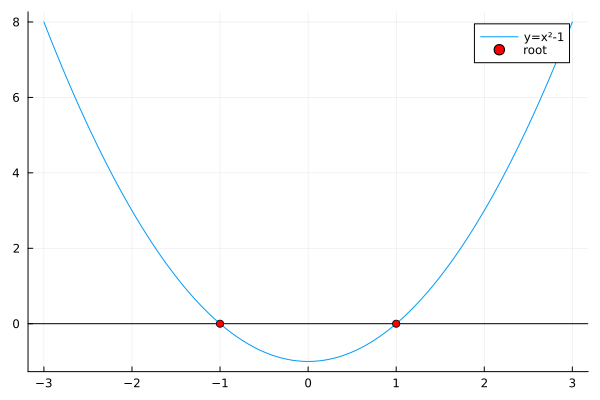

In [96]:
xs = -3:.01:3
plot(xs, [parabola(x, p) for x in xs], label = "y=x²-1", legend = :topright)
hline!([0], color = :black, label = "")
scatter!(roots, [0], color = :red, label = "root")